In [69]:
import pandas as pd

df = pd.read_csv("/home/madhav/workstation/Lab/DataSet/competion_dataset/train.csv")

i = 0
l = list(df.columns)
print(len(l))
for col in l:
    print(i, col)
    i+=1
df.head()

60
0 space_id
1 operator_ref
2 operator_platform_age_years
3 operator_platform_age_months
4 operator_active_years
5 operator_active_months
6 operator_class
7 operator_certified
8 operator_portfolio_size
9 operator_has_avatar
10 operator_id_verified
11 zone
12 borough
13 geo_lat
14 geo_lon
15 space_class
16 access_type
17 max_seats
18 utility_rooms
19 zones
20 workstations
21 facilities
22 snapshot_start_date
23 snapshot_end_date
24 min_term_days
25 max_term_days
26 min_term_floor
27 min_term_ceiling
28 max_term_floor
29 max_term_ceiling
30 min_term_avg
31 max_term_avg
32 bookable
33 open_slots_a
34 open_slots_b
35 open_slots_c
36 open_slots_d
37 review_count
38 review_count_12m
39 review_count_30d
40 open_slots_e
41 review_count_prev_yr
42 booked_load
43 first_review_date
44 last_review_date
45 score_overall
46 score_accuracy
47 score_condition
48 score_onboarding
49 score_support
50 score_access
51 score_value
52 compliance_status
53 operator_metro_units
54 operator_metro_whole
55 ope

,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2
3,3,Spesspe,2.0,1.0,2.0,1.0,unverified_operator,t,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.60,MTR-09,4
4,4,Gosho,2.0,7.0,2.0,4.0,unverified_operator,t,1.0,t,...,9.42,9.74,licensed,1,1,0,0,4.64,MTR-08,3


## <center> Data Ingestion </center>

Sequence
1. Data Exploration
2. Inspection for cleaning routine
3. Picking best features
4. Filtering out noise
5. Final dataset for preprocessing

In [70]:
# Foundational Numerical data points based model

# Top ranking dataset pick from feature set
numerical_features = [2, 3, 4, 5, 13, 14, 57,59]

training_numericals = (df.iloc[:,numerical_features]).copy(deep=True)

# New Feature Build 
active_years = training_numericals['operator_platform_age_years']*(12*30) + training_numericals['operator_platform_age_months']*30

# New Feature uploading into main data frame of interest
train_data = pd.DataFrame({
    "age":active_years,
    "geo_lat":training_numericals['geo_lat'],
    "geo_lon":training_numericals['geo_lon'],
    "reviews_per_month":training_numericals['reviews_per_month']
}).copy(deep=True)



X = train_data
y = training_numericals['price_tier']

# Null handle 


X['age'] = X['age'].fillna(X['age'].mean())
X['reviews_per_month'] = X['reviews_per_month'].fillna(0)

print(X.isna().sum())
X.shape, y.shape


age                  0
geo_lat              0
geo_lon              0
reviews_per_month    0
dtype: int64


((279746, 4), (279746,))

Accuracy: 0.40
              precision    recall  f1-score   support

      Tier 1       0.50      0.65      0.56     13507
      Tier 2       0.45      0.12      0.19     16268
      Tier 3       0.27      0.45      0.34     11955
      Tier 4       0.45      0.45      0.45     14220

    accuracy                           0.40     55950
   macro avg       0.42      0.42      0.39     55950
weighted avg       0.42      0.40      0.38     55950



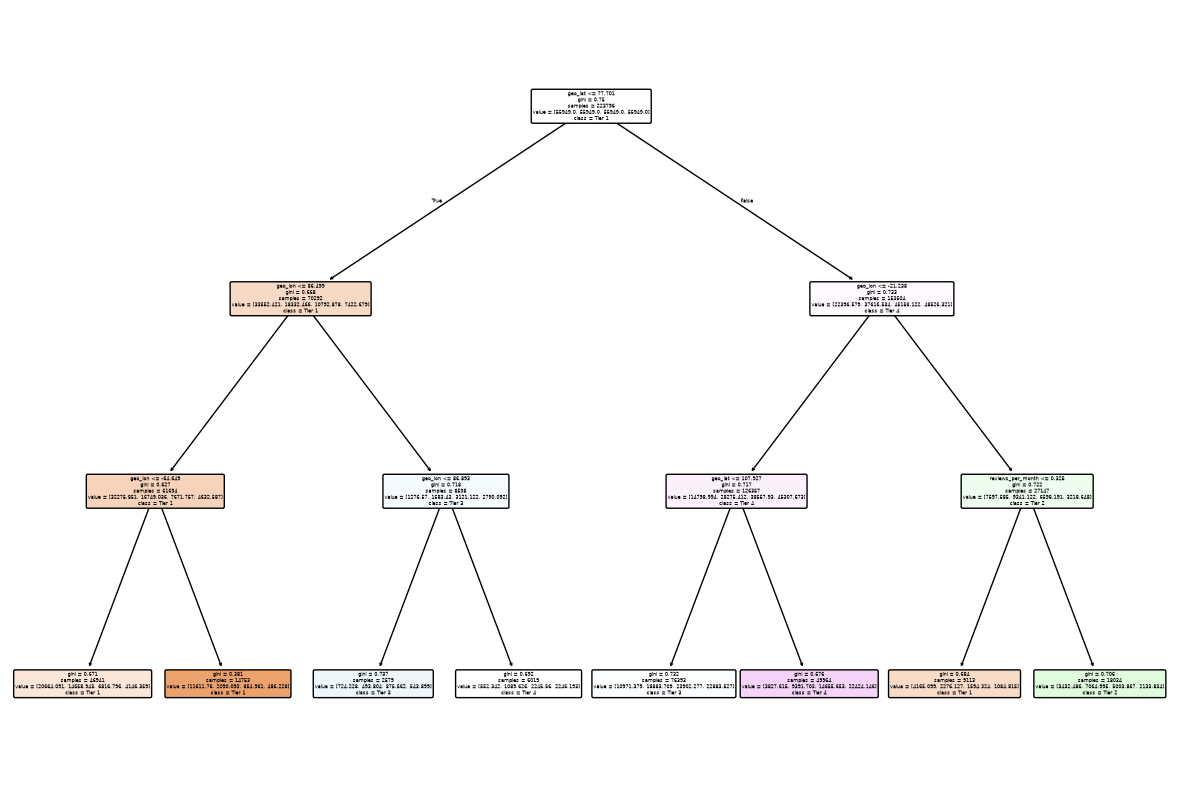

In [74]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Model Config
DEPTH = 3
RANDOM_STATE = 34

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# Initiating decision tree model with your configuration constants
clf = DecisionTreeClassifier(max_depth=DEPTH, random_state=RANDOM_STATE, class_weight='balanced')

# Train the model
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Define your string class names for reporting and visualization (ordered 1 to 4)
class_names = ["Tier 1", "Tier 2", "Tier 3", "Tier 4"]

# Step 6: Evaluate performance
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print(
    classification_report(y_test, y_pred, target_names=class_names, zero_division=0)
)

# Step 7: Visualize the decision rules
plt.figure(figsize=(15, 10))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=class_names,
    filled=True,
    rounded=True,
)
plt.show()
